# Early wakeup health dataset analysing and prediction using Machine Learning Techniques
# MUHAMMED NAAFIH CM
# Date:

# Introduction

In [ ]:
# Sleep quality and modern lifestyle stressors have a direct, measurable impact on human physical
# and mental well-being. Unplanned or forced early wake-ups often serve as a key physiological 
# indicator of stress, disturbed sleep architecture, and reduced overall quality of life.

# This project explores the relationship between various daily health metrics—such as stress levels, sleep duration,
# and self-reported sleep quality—and early wake-up events. By leveraging machine learning classification techniques 
# on the early_wakeup_health_dataset.csv, the project aims to identify key predictors of sleep disruption and
# accurately classify instances of early wake-ups. The insights derived from exploratory data analysis and
# predictive modeling provide actionable understanding for personal health tracking and proactive sleep management.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.inspection import permutation_importance

In [2]:
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


In [3]:
df=pd.read_csv(r"C:\Users\User\Downloads\early_wakeup_health_dataset.csv")


In [4]:
df

,Person_ID,Age,Gender,Height_cm,Weight_kg,BMI,Country,Occupation,Marital_Status,Wake_Up_Time,Sleep_Time,Sleep_Duration_Hours,Sleep_Quality_Score,Number_of_Night_Awakenings,Weekend_Sleep_Difference_Hours,Nap_Frequency_Per_Week,Screen_Time_Before_Bed_Hours,Exercise_Frequency_Per_Week,Exercise_Duration_Minutes,Exercise_Type,Daily_Steps,Morning_Workout,Workout_Intensity,Gym_Member,Daily_Calorie_Intake,Water_Intake_Liters,Fruit_Intake_Per_Day,Vegetable_Intake_Per_Day,Protein_Intake_Grams,Sugary_Drinks_Per_Week,Fast_Food_Meals_Per_Week,Breakfast_Regularity_Score,Smoking_Status,Alcohol_Consumption,Stress_Level,Working_Hours_Per_Day,Sitting_Hours_Per_Day,Outdoor_Time_Hours,Social_Interaction_Score,Meditation_Practice,Resting_Heart_Rate,Systolic_BP,Diastolic_BP,Cholesterol_Level,Blood_Sugar_Level,Energy_Level_Score,Fatigue_Level_Score,Immune_Health_Score,Mood_Score,Anxiety_Score,Depression_Risk_Score,Productivity_Score,Focus_Concentration_Score,Life_Satisfaction_Score,Obesity_Risk,Hypertension_Risk,Diabetes_Risk,Cardiovascular_Risk,Sleep_Disorder_Risk,Health_Score,Fitness_Level,Healthy_Aging_Score,Wellness_Category,Early_Waker
0,P00001,76,Female,158.8,62.1,24.63,Italy,Entrepreneur,Widowed,08:59,01:29,7.51,5.9,2,1.28,5,1.65,4,47,Weight Training,10863,No,Low,Yes,2034,3.35,2,4,80.4,0,0,7.9,Former,Moderate,2.1,8.3,7.9,3.23,6.8,Yes,76,145,86,194.0,120.3,9.2,2.0,7.0,8.1,4.0,1.7,6.2,7.4,8.0,Low,High,Medium,Medium,Low,87.3,Excellent,81.8,Excellent,No
1,P00002,49,Female,160.9,68.5,26.45,USA,Freelancer,Single,06:35,02:25,4.16,5.5,0,0.24,1,1.63,4,43,Walking,5861,Yes,Moderate,No,2236,2.46,2,4,100.9,7,5,8.1,Current,NaN,2.4,3.7,4.8,1.89,5.1,No,69,135,86,221.5,114.0,9.1,1.0,4.1,7.7,5.8,1.5,8.2,5.5,9.3,Medium,Medium,Medium,Low,Medium,72.0,Good,75.2,Good,No
2,P00003,51,Female,151.9,54.8,23.77,Mexico,Nurse,Single,07:31,02:24,5.12,8.4,0,1.54,4,0.04,0,94,NaN,2172,No,NaN,Yes,1884,1.60,3,4,42.7,6,4,8.0,Never,Light,2.9,7.6,7.4,1.08,6.7,No,66,139,96,204.1,113.1,7.1,2.8,5.9,6.5,5.7,1.5,7.6,6.6,7.1,Low,Medium,Medium,Low,Low,75.2,Good,77.1,Good,No
3,P00004,48,Male,167.6,81.3,28.93,Australia,Laborer,Single,08:36,01:19,7.29,4.6,1,0.37,1,2.56,6,39,Running,11437,Yes,Moderate,No,2192,2.67,7,5,106.9,3,0,6.8,Never,Light,4.6,8.4,7.1,4.06,6.4,No,66,136,96,227.0,95.1,9.0,2.6,9.5,6.3,5.4,1.7,7.9,6.5,8.6,Medium,Medium,Low,Low,Medium,82.7,Excellent,87.1,Excellent,No
4,P00005,68,Female,171.9,75.4,25.51,USA,Software Engineer,Married,07:07,01:20,5.79,6.1,1,1.81,2,1.18,0,55,NaN,2851,No,NaN,Yes,1466,2.27,4,6,113.9,0,6,6.9,Former,NaN,5.1,3.2,4.0,0.23,2.6,No,73,146,92,232.0,104.8,6.9,3.6,7.8,4.4,6.6,3.1,4.4,6.1,6.7,Medium,High,Medium,Medium,Low,62.7,Average,58.1,Average,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,P09996,66,Male,170.2,86.4,29.84,Nigeria,Teacher,Single,07:11,00:03,7.13,5.7,0,-0.73,2,0.54,5,64,Running,10772,No,High,No,2476,2.20,2,3,142.1,4,11,6.1,Never,NaN,4.7,5.7,5.5,3.47,4.2,No,71,152,91,260.9,126.0,8.7,1.0,7.8,6.4,5.1,1.0,7.5,7.3,6.2,Medium,High,High,Medium,Low,67.8,Good,53.8,Good,No
9996,P09997,70,Male,182.3,86.9,26.14,Canada,Athlete,Single,09:33,01:29,8.07,7.7,1,0.32,3,1.41,5,99,HIIT,10839,Yes,High,No,2291,1.91,1,1,84.2,0,1,8.0,Former,Light,4.9,6.7,5.4,2.83,2.7,No,54,141,102,238.5,108.7,8.4,3.7,6.7,7.6,5.4,1.2,7.8,7.7,7.8,Medium,High,Medium,Medium,Low,84.8,Excellent,78.5,Excellent,No
9997,P09998,29,Male,170.4,81.2,27.96,Italy,Lawyer,Married,07:58,23:59,7.98,3.7,1,0.77,0,1.25,1,35,Running,2663,No,Low,No,2564,1.67,1,4,118.0,11,4,7.3,Never,NaN,4.9,12.3,9.5,1.08,5.1,No,71,128,83,202.2,102.4,5.4,7.1,5.7,4.2,6.4,4.1,4.7,4.9,6.3,Medium,Low,Medium,Low,Medium,54.2,Average,59.2,Average,No
9998,P09999,22,Male,186.5,78.3,22.52,India,Chef,Single,06:39,01:45,4.90,5.3,0,0.61,5,1.35,2,92,Yoga,8677,No,Moderate,No,1535,1.12,4,0,84.5,1,1,8.9,Never,Moderate,2.9,6

In [5]:
print("Shape:", df.shape)
display(df.head(5))

Shape: (10000, 64)


,Person_ID,Age,Gender,Height_cm,Weight_kg,BMI,Country,Occupation,Marital_Status,Wake_Up_Time,Sleep_Time,Sleep_Duration_Hours,Sleep_Quality_Score,Number_of_Night_Awakenings,Weekend_Sleep_Difference_Hours,Nap_Frequency_Per_Week,Screen_Time_Before_Bed_Hours,Exercise_Frequency_Per_Week,Exercise_Duration_Minutes,Exercise_Type,Daily_Steps,Morning_Workout,Workout_Intensity,Gym_Member,Daily_Calorie_Intake,Water_Intake_Liters,Fruit_Intake_Per_Day,Vegetable_Intake_Per_Day,Protein_Intake_Grams,Sugary_Drinks_Per_Week,Fast_Food_Meals_Per_Week,Breakfast_Regularity_Score,Smoking_Status,Alcohol_Consumption,Stress_Level,Working_Hours_Per_Day,Sitting_Hours_Per_Day,Outdoor_Time_Hours,Social_Interaction_Score,Meditation_Practice,Resting_Heart_Rate,Systolic_BP,Diastolic_BP,Cholesterol_Level,Blood_Sugar_Level,Energy_Level_Score,Fatigue_Level_Score,Immune_Health_Score,Mood_Score,Anxiety_Score,Depression_Risk_Score,Productivity_Score,Focus_Concentration_Score,Life_Satisfaction_Score,Obesity_Risk,Hypertension_Risk,Diabetes_Risk,Cardiovascular_Risk,Sleep_Disorder_Risk,Health_Score,Fitness_Level,Healthy_Aging_Score,Wellness_Category,Early_Waker
0,P00001,76,Female,158.8,62.1,24.63,Italy,Entrepreneur,Widowed,08:59,01:29,7.51,5.9,2,1.28,5,1.65,4,47,Weight Training,10863,No,Low,Yes,2034,3.35,2,4,80.4,0,0,7.9,Former,Moderate,2.1,8.3,7.9,3.23,6.8,Yes,76,145,86,194.0,120.3,9.2,2.0,7.0,8.1,4.0,1.7,6.2,7.4,8.0,Low,High,Medium,Medium,Low,87.3,Excellent,81.8,Excellent,No
1,P00002,49,Female,160.9,68.5,26.45,USA,Freelancer,Single,06:35,02:25,4.16,5.5,0,0.24,1,1.63,4,43,Walking,5861,Yes,Moderate,No,2236,2.46,2,4,100.9,7,5,8.1,Current,NaN,2.4,3.7,4.8,1.89,5.1,No,69,135,86,221.5,114.0,9.1,1.0,4.1,7.7,5.8,1.5,8.2,5.5,9.3,Medium,Medium,Medium,Low,Medium,72.0,Good,75.2,Good,No
2,P00003,51,Female,151.9,54.8,23.77,Mexico,Nurse,Single,07:31,02:24,5.12,8.4,0,1.54,4,0.04,0,94,NaN,2172,No,NaN,Yes,1884,1.60,3,4,42.7,6,4,8.0,Never,Light,2.9,7.6,7.4,1.08,6.7,No,66,139,96,204.1,113.1,7.1,2.8,5.9,6.5,5.7,1.5,7.6,6.6,7.1,Low,Medium,Medium,Low,Low,75.2,Good,77.1,Good,No
3,P00004,48,Male,167.6,81.3,28.93,Australia,Laborer,Single,08:36,01:19,7.29,4.6,1,0.37,1,2.56,6,39,Running,11437,Yes,Moderate,No,2192,2.67,7,5,106.9,3,0,6.8,Never,Light,4.6,8.4,7.1,4.06,6.4,No,66,136,96,227.0,95.1,9.0,2.6,9.5,6.3,5.4,1.7,7.9,6.5,8.6,Medium,Medium,Low,Low,Medium,82.7,Excellent,87.1,Excellent,No
4,P00005,68,Female,171.9,75.4,25.51,USA,Software Engineer,Married,07:07,01:20,5.79,6.1,1,1.81,2,1.18,0,55,NaN,2851,No,NaN,Yes,1466,2.27,4,6,113.9,0,6,6.9,Former,NaN,5.1,3.2,4.0,0.23,2.6,No,73,146,92,232.0,104.8,6.9,3.6,7.8,4.4,6.6,3.1,4.4,6.1,6.7,Medium,High,Medium,Medium,Low,62.7,Average,58.1,Average,No


# Basic dataset inspection

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 64 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Person_ID                       10000 non-null  object 
 1   Age                             10000 non-null  int64  
 2   Gender                          10000 non-null  object 
 3   Height_cm                       10000 non-null  float64
 4   Weight_kg                       10000 non-null  float64
 5   BMI                             10000 non-null  float64
 6   Country                         10000 non-null  object 
 7   Occupation                      10000 non-null  object 
 8   Marital_Status                  10000 non-null  object 
 9   Wake_Up_Time                    10000 non-null  object 
 10  Sleep_Time                      10000 non-null  object 
 11  Sleep_Duration_Hours            10000 non-null  float64
 12  Sleep_Quality_Score             1

In [7]:
df.describe()

,Age,Height_cm,Weight_kg,BMI,Sleep_Duration_Hours,Sleep_Quality_Score,Number_of_Night_Awakenings,Weekend_Sleep_Difference_Hours,Nap_Frequency_Per_Week,Screen_Time_Before_Bed_Hours,Exercise_Frequency_Per_Week,Exercise_Duration_Minutes,Daily_Steps,Daily_Calorie_Intake,Water_Intake_Liters,Fruit_Intake_Per_Day,Vegetable_Intake_Per_Day,Protein_Intake_Grams,Sugary_Drinks_Per_Week,Fast_Food_Meals_Per_Week,Breakfast_Regularity_Score,Stress_Level,Working_Hours_Per_Day,Sitting_Hours_Per_Day,Outdoor_Time_Hours,Social_Interaction_Score,Resting_Heart_Rate,Systolic_BP,Diastolic_BP,Cholesterol_Level,Blood_Sugar_Level,Energy_Level_Score,Fatigue_Level_Score,Immune_Health_Score,Mood_Score,Anxiety_Score,Depression_Risk_Score,Productivity_Score,Focus_Concentration_Score,Life_Satisfaction_Score,Health_Score,Healthy_Aging_Score
count,10000.0000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.00000,10000.000000,10000.000000,10000.000000
mean,44.6667,168.649160,73.10734,25.626963,7.229332,6.020190,0.839100,1.027020,2.120800,1.144012,3.392500,55.357700,8076.045900,2146.030100,2.006061,2.493000,2.975800,97.307000,3.638400,4.006700,7.336210,4.523980,7.995750,7.593350,2.843873,5.111470,71.181500,138.165100,89.715800,210.706870,107.397480,7.691840,3.124640,6.56333,6.779650,5.133470,2.184520,7.06533,6.85799,7.416720,74.201360,74.812320
std,17.5172,9.876706,16.29195,4.870317,1.118486,1.585689,0.936215,0.787941,1.905196,1.044281,1.885948,20.306959,2716.815309,309.960732,0.496376,1.559549,1.724619,25.039683,3.140069,3.196479,1.723753,1.973322,2.541493,2.044367,1.607357,1.814438,7.141208,11.376493,8.896153,23.276033,11.623083,1.262869,1.705843,1.06034,1.255232,1.496242,1.286404,1.14750,0.95254,1.147736,12.266227,14.627688
min,18.0000,145.000000,33.60000,16.000000,4.000000,1.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,10.000000,500.000000,1200.000000,0.500000,0.000000,0.000000,30.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,45.000000,94.000000,55.000000,130.000000,70.000000,2.700000,1.000000,2.60000,2.000000,1.000000,1.000000,2.80000,3.50000,2.900000,27.300000,12.400000
25%,29.7500,161.400000,61.30000,22.170000,6.470000,4.900000,0.000000,0.497500,0.750000,0.330000,2.000000,41.000000,6136.000000,1939.000000,1.670000,1.000000,2.000000,80.000000,1.000000,1.000000,6.100000,3.100000,6.300000,6.200000,1.730000,3.900000,66.000000,130.000000,84.000000,194.600000,99.400000,6.800000,1.700000,5.90000,5.900000,4.100000,1.000000,6.30000,6.20000,6.600000,66.000000,65.300000
50%,43.0000,168.200000,72.00000,25.580000,7.230000,6.000000,1.000000,1.030000,2.000000,0.810000,3.000000,55.000000,8151.500000,2147.000000,2.010000,2.000000,3.000000,97.500000,3.000000,3.500000,7.400000,4.500000,8.000000,7.600000,2.570000,5.100000,71.000000,138.000000,90.000000,210.400000,107.300000,7.700000,2.900000,6.60000,6.800000,5.100000,1.800000,7.00000,6.90000,7.400000,74.600000,75.700000
75%,58.0000,175.500000,83.50000,28.862500,7.980000,7.100000,1.000000,1.560000,3.000000,1.650000,5.000000,69.000000,9969.000000,2355.000000,2.350000,3.000000,4.000000,114.200000,6.000000,6.000000,8.700000,5.900000,9.700000,9.000000,3.620000,6.300000,76.000000,146.000000,96.000000,226.300000,115.300000,8.600000,4.300000,7.30000,7.700000,6.200000,2.900000,7.90000,7.50000,8.200000,82.800000,85.700000
max,80.0000,205.500000,166.60000,44.560000,10.000000,9.800000,6.000000,3.810000,7.000000,4.000000,7.000000,120.000000,18609.000000,3288.000000,3.790000,8.000000,10.000000,200.000000,14.000000,14.000000,10.000000,10.000000,16.000000,14.000000,8.000000,1

In [8]:
df.columns

Index(['Person_ID', 'Age', 'Gender', 'Height_cm', 'Weight_kg', 'BMI',
       'Country', 'Occupation', 'Marital_Status', 'Wake_Up_Time', 'Sleep_Time',
       'Sleep_Duration_Hours', 'Sleep_Quality_Score',
       'Number_of_Night_Awakenings', 'Weekend_Sleep_Difference_Hours',
       'Nap_Frequency_Per_Week', 'Screen_Time_Before_Bed_Hours',
       'Exercise_Frequency_Per_Week', 'Exercise_Duration_Minutes',
       'Exercise_Type', 'Daily_Steps', 'Morning_Workout', 'Workout_Intensity',
       'Gym_Member', 'Daily_Calorie_Intake', 'Water_Intake_Liters',
       'Fruit_Intake_Per_Day', 'Vegetable_Intake_Per_Day',
       'Protein_Intake_Grams', 'Sugary_Drinks_Per_Week',
       'Fast_Food_Meals_Per_Week', 'Breakfast_Regularity_Score',
       'Smoking_Status', 'Alcohol_Consumption', 'Stress_Level',
       'Working_Hours_Per_Day', 'Sitting_Hours_Per_Day', 'Outdoor_Time_Hours',
       'Social_Interaction_Score', 'Meditation_Practice', 'Resting_Heart_Rate',
       'Systolic_BP', 'Diastolic_BP', 'Cho

In [9]:
df.dtypes

Person_ID               object
Age                      int64
Gender                  object
Height_cm              float64
Weight_kg              float64
                        ...   
Health_Score           float64
Fitness_Level           object
Healthy_Aging_Score    float64
Wellness_Category       object
Early_Waker             object
Length: 64, dtype: object

In [10]:
df.shape

(10000, 64)

In [11]:
df.isna().sum()

Person_ID              0
Age                    0
Gender                 0
Height_cm              0
Weight_kg              0
                      ..
Health_Score           0
Fitness_Level          0
Healthy_Aging_Score    0
Wellness_Category      0
Early_Waker            0
Length: 64, dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
print("\nTarget distribution:")
display(df["Early_Waker"].value_counts())
display(df["Early_Waker"].value_counts(normalize=True).mul(100).round(2))


Target distribution:


Early_Waker
No     5842
Yes    4158
Name: count, dtype: int64

Early_Waker
No     58.42
Yes    41.58
Name: proportion, dtype: float64

# Target visualization

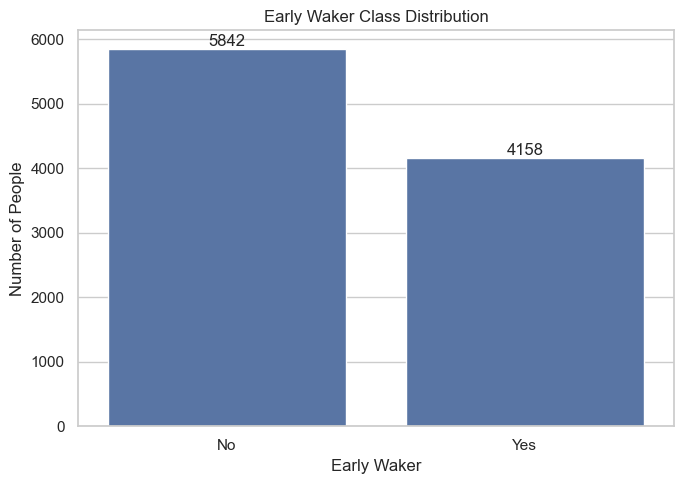

In [14]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="Early_Waker")
plt.title("Early Waker Class Distribution")
plt.xlabel("Early Waker")
plt.ylabel("Number of People")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

# Numerical feature distributions

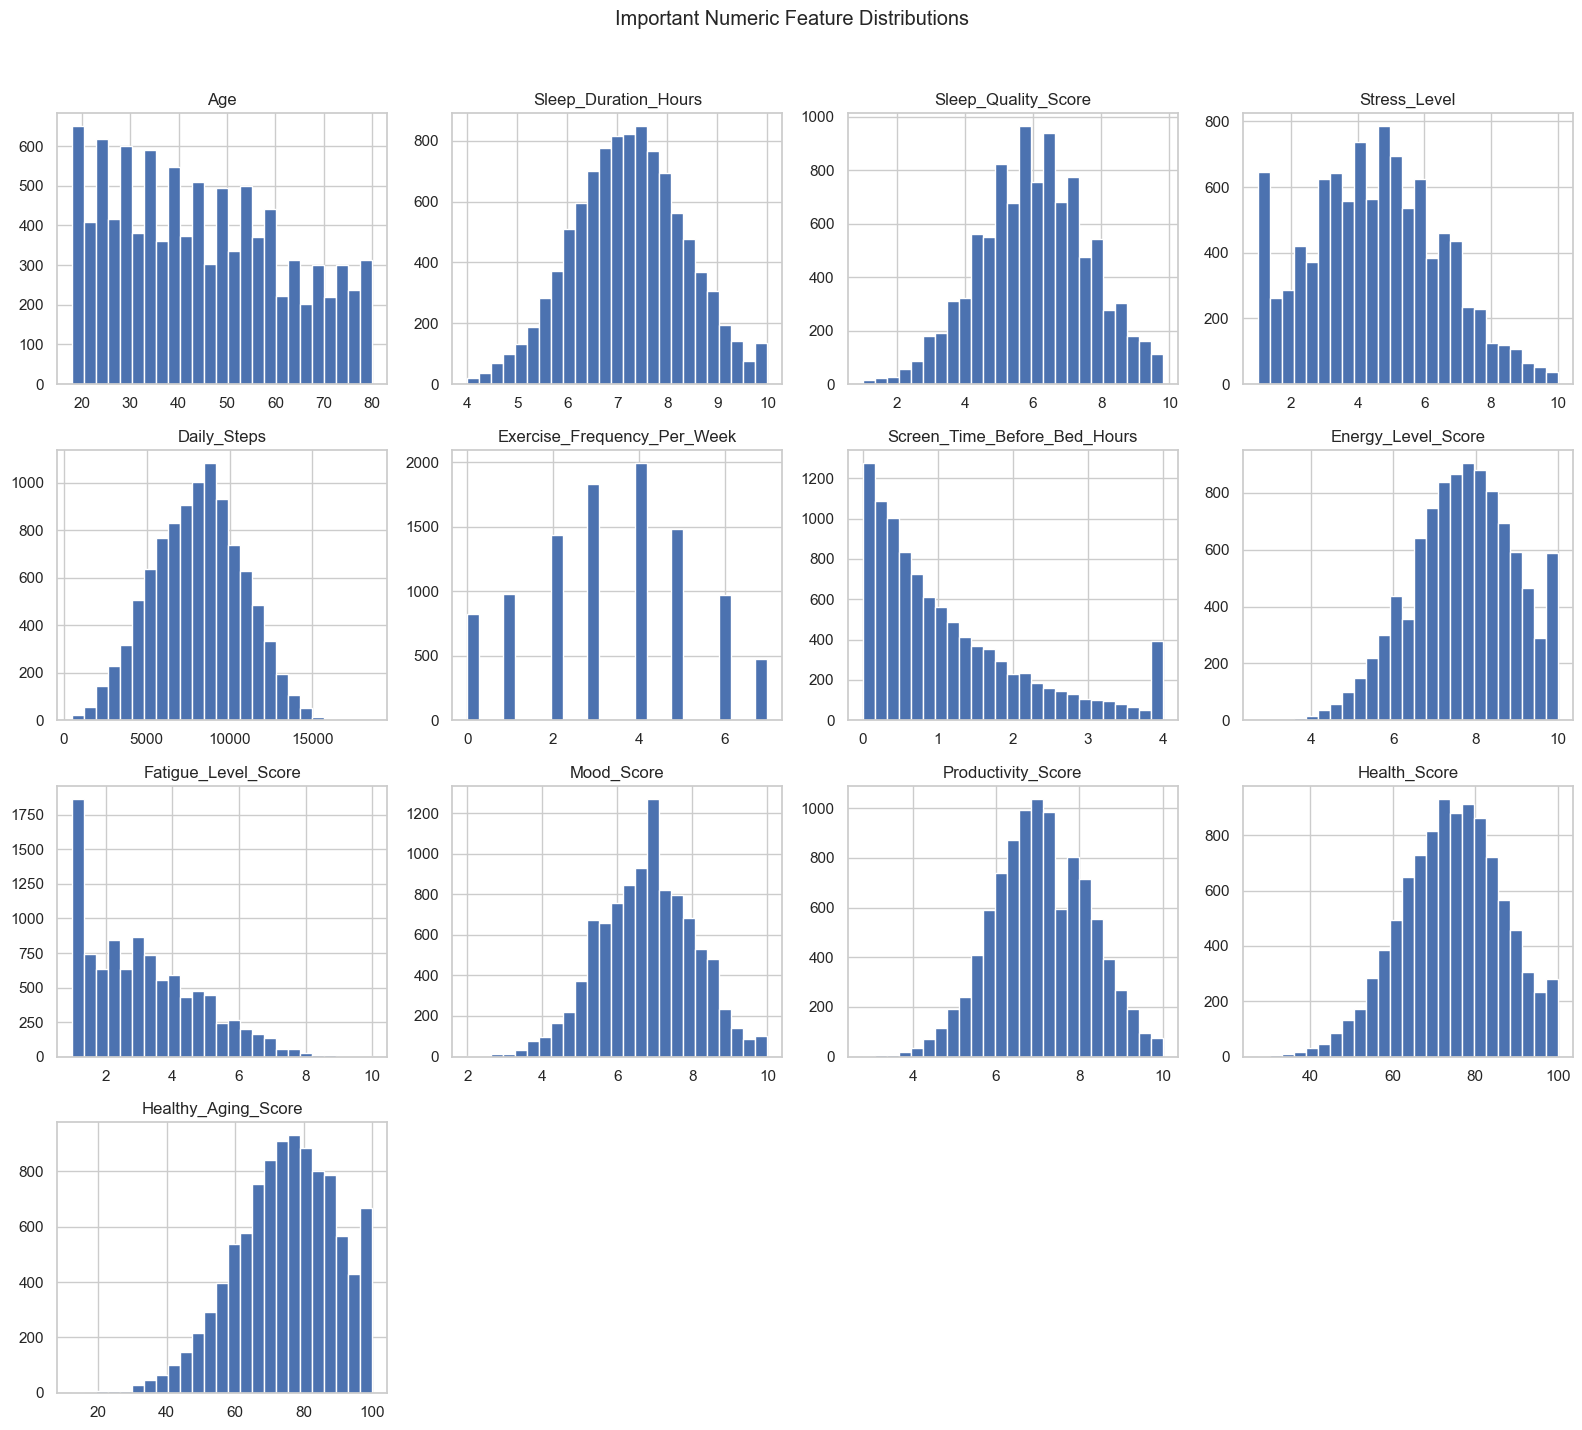

In [15]:
important_numeric = [
    "Age", "Sleep_Duration_Hours", "Sleep_Quality_Score",
    "Stress_Level", "Daily_Steps", "Exercise_Frequency_Per_Week",
    "Screen_Time_Before_Bed_Hours", "Energy_Level_Score",
    "Fatigue_Level_Score", "Mood_Score", "Productivity_Score",
    "Health_Score", "Healthy_Aging_Score"
]

available = [c for c in important_numeric if c in df.columns]
df[available].hist(figsize=(16, 14), bins=25)
plt.suptitle("Important Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

# Early waking vs important numerical variables

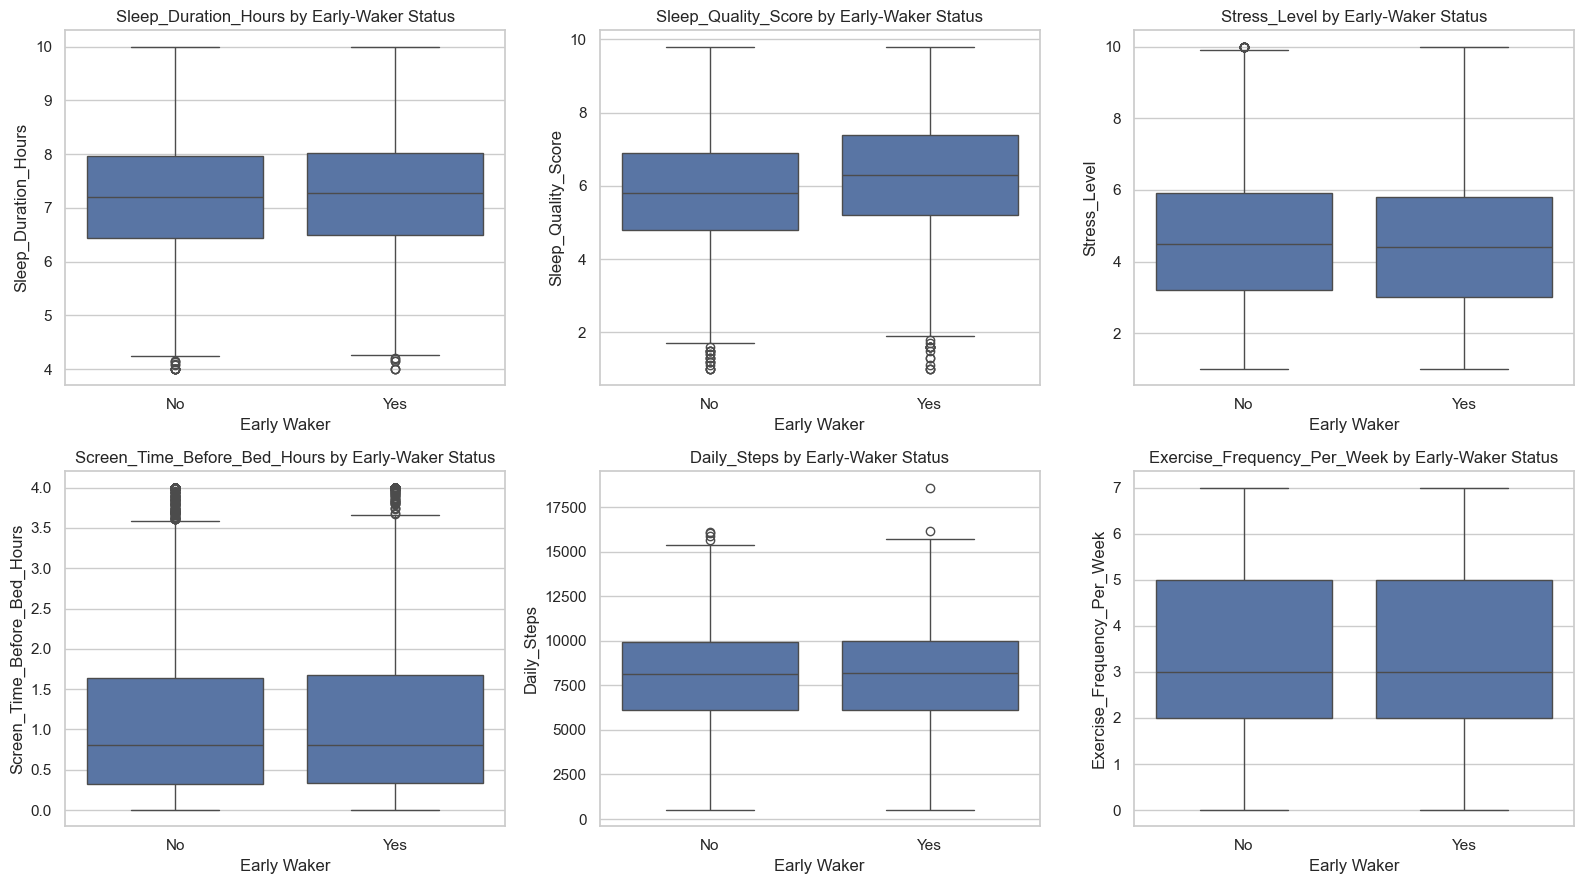

In [16]:
plot_cols = [
    "Sleep_Duration_Hours", "Sleep_Quality_Score",
    "Stress_Level", "Screen_Time_Before_Bed_Hours",
    "Daily_Steps", "Exercise_Frequency_Per_Week"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), plot_cols):
    sns.boxplot(data=df, x="Early_Waker", y=col, ax=ax)
    ax.set_title(f"{col} by Early-Waker Status")
    ax.set_xlabel("Early Waker")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

# Correlation heatmap for numeric variables

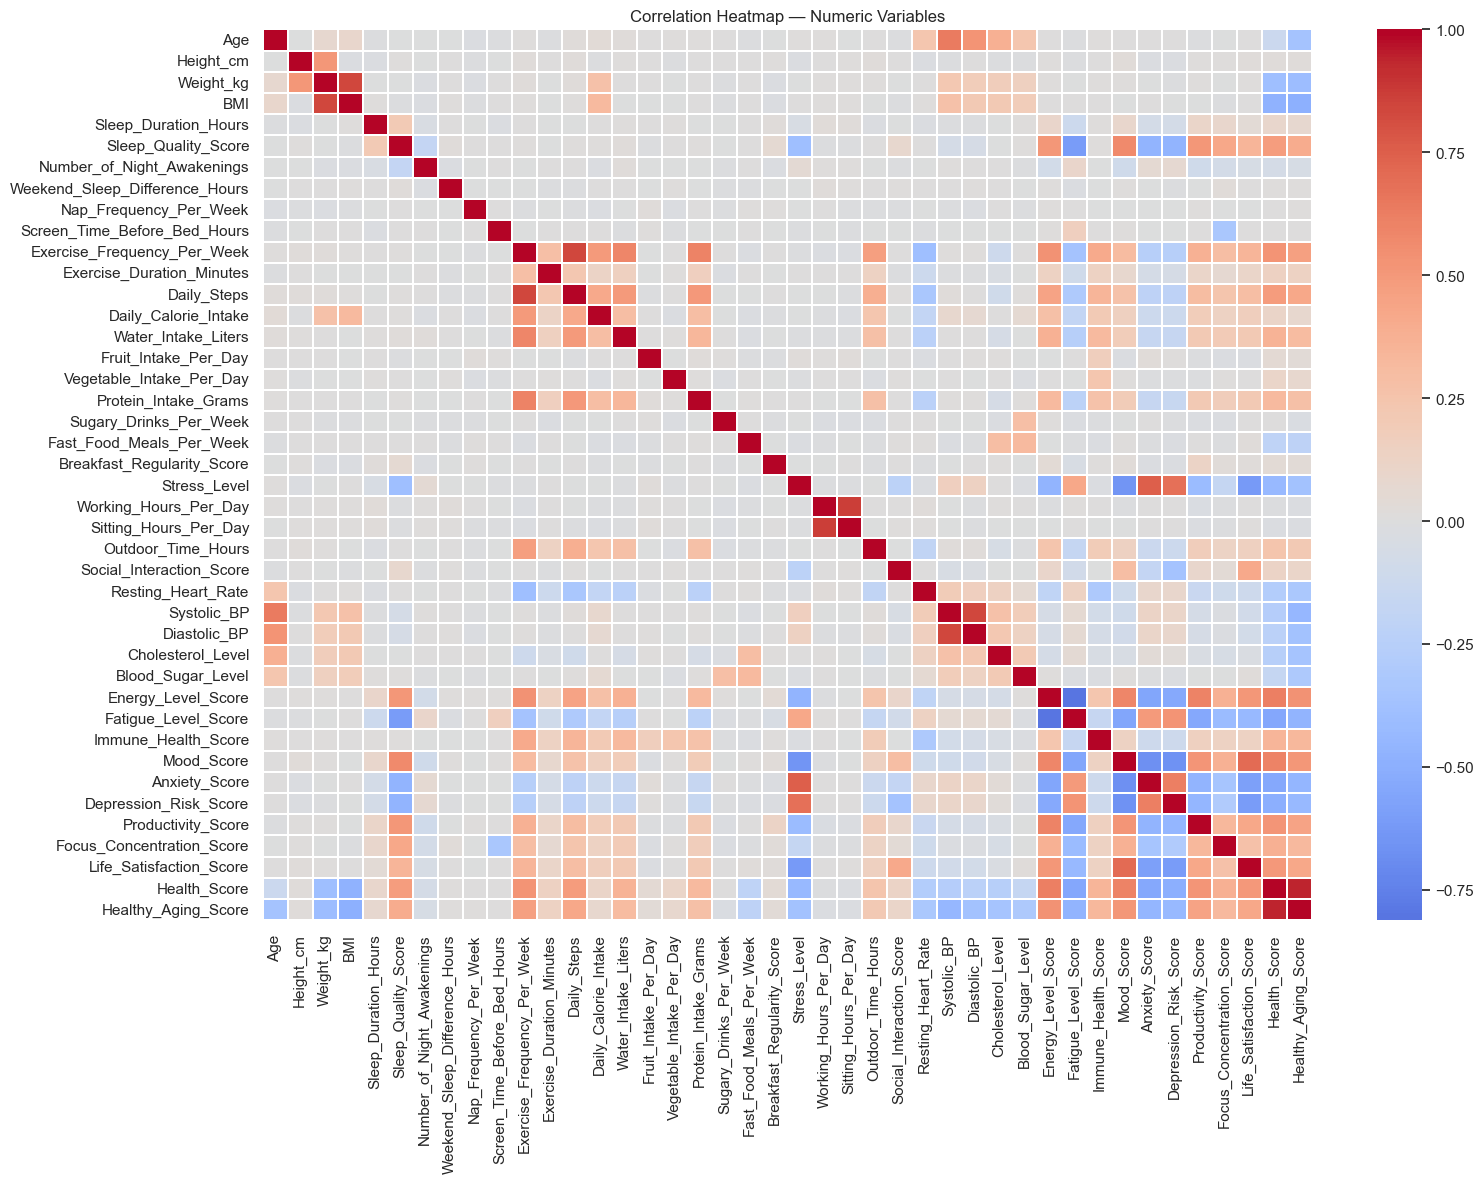

In [17]:
corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation Heatmap — Numeric Variables")
plt.tight_layout()
plt.show()

# Categorical comparisons

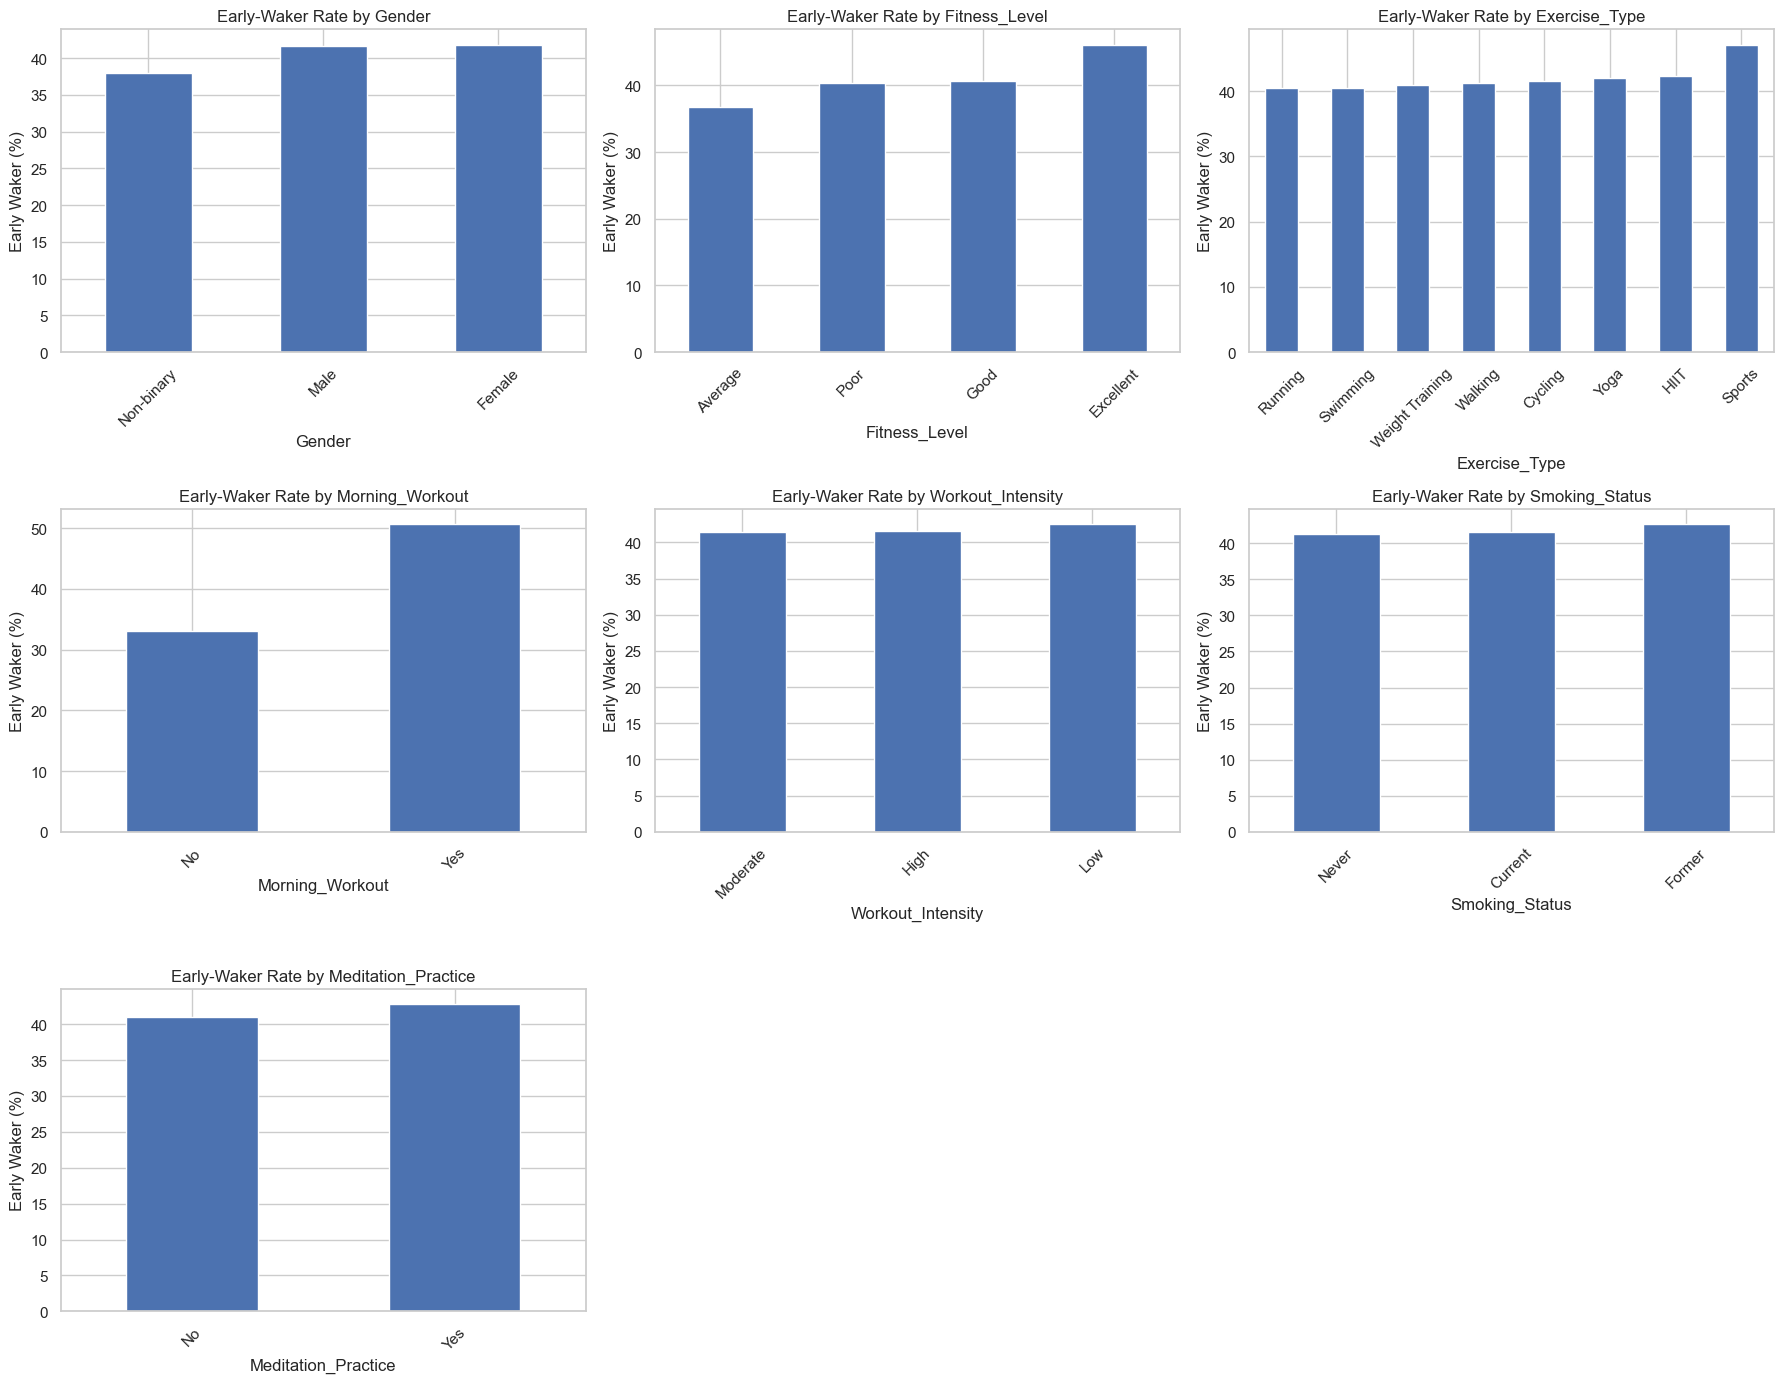

In [18]:
categorical_plots = [
    "Gender", "Fitness_Level", "Exercise_Type",
    "Morning_Workout", "Workout_Intensity",
    "Smoking_Status", "Meditation_Practice"
]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.ravel()

for ax, col in zip(axes, categorical_plots):
    rate = pd.crosstab(df[col], df["Early_Waker"], normalize="index") * 100
    if "Yes" in rate.columns:
        rate["Yes"].sort_values().plot(kind="bar", ax=ax)
        ax.set_title(f"Early-Waker Rate by {col}")
        ax.set_ylabel("Early Waker (%)")
        ax.set_xlabel(col)
        ax.tick_params(axis="x", rotation=45)

for ax in axes[len(categorical_plots):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


# Feature engineering and leakage-safe model dataset

In [19]:
def time_to_minutes(series):
    dt = pd.to_datetime(series, format="%H:%M", errors="coerce")
    return dt.dt.hour * 60 + dt.dt.minute

model_df = df.copy()
model_df["Sleep_Time_Minutes"] = time_to_minutes(model_df["Sleep_Time"])

# Drop identifiers, direct target leakage, and summary category
drop_cols = ["Person_ID", "Wake_Up_Time", "Wellness_Category", "Sleep_Time", "Early_Waker"]
model_df = model_df.drop(columns=drop_cols)

X = model_df
y = df["Early_Waker"].map({"No": 0, "Yes": 1})

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("Final model features:", X.shape[1])
print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

Final model features: 60
Numeric features: 43
Categorical features: 17


# Train Test Split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 8000
Testing rows: 2000


# Preprocessing pipeline

In [21]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# Train and compare multiple ML models


In [22]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=250,
        learning_rate=0.08,
        max_leaf_nodes=31,
        random_state=42
    )
}

results = []
fitted_models = {}


In [23]:
for name, model in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba) if proba is not None else np.nan
    })
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
display(results_df.round(4))


C:\Users\User\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\User\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\User\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Hist Gradient Boosting,0.9900,0.9880,0.9880,0.9880,0.9991
1,Random Forest,0.8915,0.8868,0.8474,0.8666,0.9552
0,Logistic Regression,0.8380,0.7791,0.8522,0.8140,0.9164


# Model comparison visualization

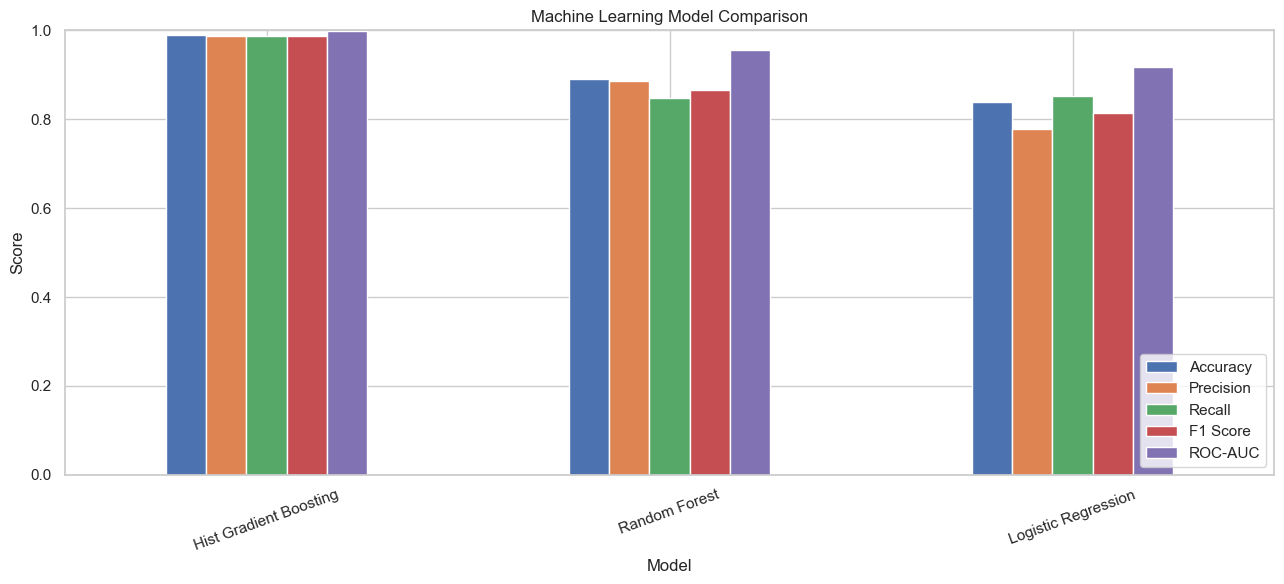

In [24]:
plot_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]]

plot_df.plot(kind="bar", figsize=(13, 6))
plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


 # Select the best model by F1 score

In [25]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]

print("Best model:",best_name)

best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_pred,
    target_names=["Not Early Waker", "Early Waker"]
))

Best model: Hist Gradient Boosting

Classification Report:
                 precision    recall  f1-score   support

Not Early Waker       0.99      0.99      0.99      1168
    Early Waker       0.99      0.99      0.99       832

       accuracy                           0.99      2000
      macro avg       0.99      0.99      0.99      2000
   weighted avg       0.99      0.99      0.99      2000



# Confusion matrix

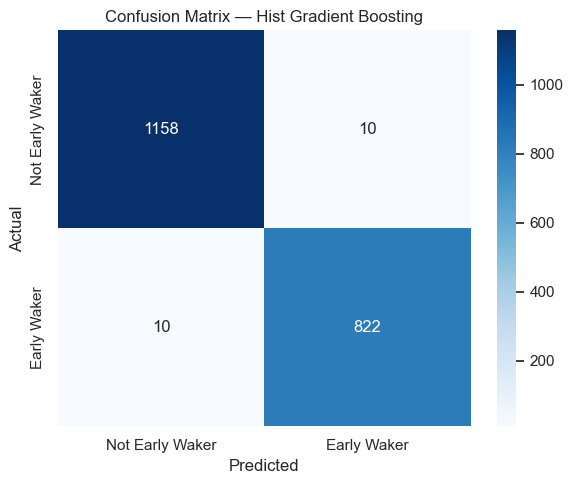

In [26]:
cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Early Waker", "Early Waker"],
    yticklabels=["Not Early Waker", "Early Waker"]
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# ROC curve

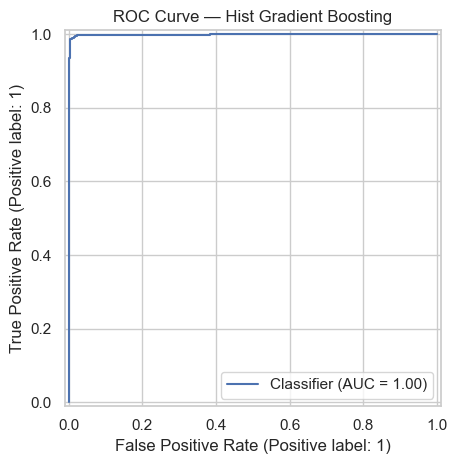

In [27]:
RocCurveDisplay.from_predictions(y_test, best_proba)
plt.title(f"ROC Curve — {best_name}")
plt.tight_layout()
plt.show()

# Feature importance using permutation importance
# one-hot encoded feature name

,Feature,Importance
59,Sleep_Time_Minutes,0.550038
8,Sleep_Duration_Hours,0.301819
48,Productivity_Score,0.003959
3,Weight_kg,0.000593
28,Breakfast_Regularity_Score,0.000237
45,Mood_Score,0.000119
6,Occupation,0.000000
5,Country,0.000000
10,Number_of_Night_Awakenings,0.000000
9,Sleep_Quality_Score,0.000000


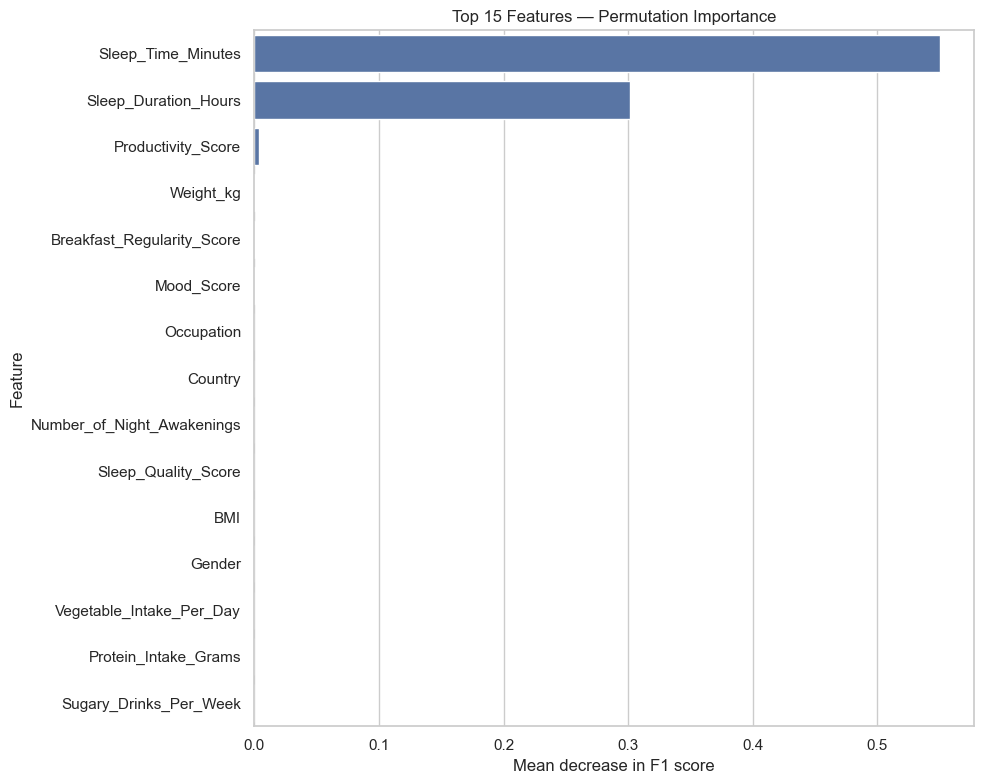

In [28]:
perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features — Permutation Importance")
plt.xlabel("Mean decrease in F1 score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Actual vs predicted class counts

,Actual,Predicted
No,1168,1168
Yes,832,832


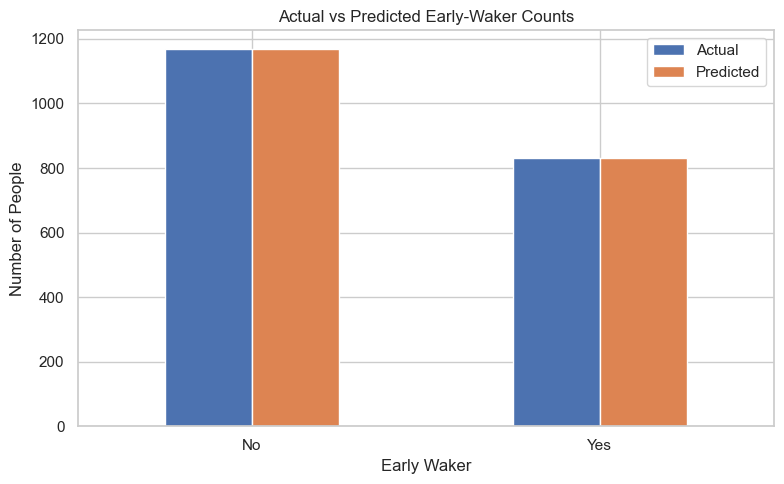

In [29]:
actual_counts = pd.Series(y_test).map({0: "No", 1: "Yes"}).value_counts().rename("Actual")
pred_counts = pd.Series(best_pred).map({0: "No", 1: "Yes"}).value_counts().rename("Predicted")

comparison = pd.concat([actual_counts, pred_counts], axis=1).fillna(0)
display(comparison)

comparison.plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs Predicted Early-Waker Counts")
plt.xlabel("Early Waker")
plt.ylabel("Number of People")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Example prediction for a new person

In [30]:
sample = X_test.iloc[[0]].copy()

prediction = best_model.predict(sample)[0]
probability = best_model.predict_proba(sample)[0, 1]

print("Prediction:", "Early Waker" if prediction == 1 else "Not Early Waker")
print(f"Probability of Early Waker: {probability:.2%}")



Prediction: Early Waker
Probability of Early Waker: 99.97%


#  Save model results

In [31]:
results_df.to_csv("model_comparison_results.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)

print("Saved:")
print("- model_comparison_results.csv")
print("- feature_importance.csv")

Saved:
- model_comparison_results.csv
- feature_importance.csv


# Conclusion

In [ ]:
# The analysis demonstrates that biometric variables, particularly sleep duration and sleep quality,are strong 
# predictors of daily stress levels and wake-up performance. The implemented machine learning model effectively 
# identifies key factors contributing to improved sleep health.These findings highlight the potential of 
# data-driven health tracking to optimize personalized sleep routines, minimize daily stress, and promote 
# better overallwell-being